# 🏙️ FalconHeat AI — Main Land Use, Heat & Exposure Analysis
## Arab Youth Space Hackathon: 813 Challenge — Theme 2

**Team:** 971 Liftoff  
**Study area:** Khalifa City, Abu Dhabi, UAE  
**Live dashboard:** https://falconheat-khalifa-city.streamlit.app

This is the **main analysis notebook** for FalconHeat. It follows the same step-by-step style as the official Theme 2 starter notebook, but uses the project's real Khalifa City Earth-observation outputs.

### What this notebook produces
- Real-data source/provenance summary
- Final FalconHeat v4.3 priority scores
- Priority ranking chart
- Heat vs built-up relationship
- Population exposure chart
- Sentinel-2 NDVI/NDBI 2021→2026 comparison
- Explainable score-contribution chart
- Static priority map
- Scenario Lab chart
- Evidence-completeness chart
- High-resolution PNG files ready for the PowerPoint

> **Important:** FalconHeat is an explainable **relative planning-priority index**, not a medical heat-health score.

In [ ]:
# Colab setup
%pip install -q pandas numpy matplotlib geopandas shapely

## Step 1 — Load the FalconHeat repository and real EO snapshot
The public competition snapshot contains the real processed Khalifa City indicators used by the deployed Streamlit app.

In [ ]:
from pathlib import Path
import os, sys, json, shutil
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

REPO_DIR = Path("/content/falconheat-khalifa-city")

if not REPO_DIR.exists():
    !git clone -q --depth 1 https://github.com/SHAIKHA2222/falconheat-khalifa-city.git

os.chdir(REPO_DIR)
sys.path.insert(0, str(REPO_DIR))

from src.analysis import run_analysis, scenario_score

RAW_CSV = REPO_DIR / "data" / "processed" / "khalifa_city_eo.csv"
META_JSON = REPO_DIR / "data" / "processed" / "khalifa_city_eo_metadata.json"

raw = pd.read_csv(RAW_CSV)
metadata = json.loads(META_JSON.read_text())
df = run_analysis(raw)

print(f"Loaded {len(df)} Khalifa City analysis polygons")
print("Published Landsat date:", metadata["landsat"]["acquisition"])
print("Published Sentinel-2 date:", metadata["sentinel2"]["acquisition"])
print("Historical Sentinel-2 date:", metadata["sentinel2_historical"]["acquisition"])

Loaded 12 Khalifa City analysis polygons
Published Landsat date: 2026-09-24
Published Sentinel-2 date: 2026-09-27
Historical Sentinel-2 date: 2021-09-18


## Step 2 — Verify data provenance
FalconHeat keeps the source IDs and observation dates traceable so the presentation can clearly distinguish measured/derived EO evidence from the decision model.

In [ ]:
print("LANDSAT")
print(metadata["landsat"]["item_id"])
print()

print("SENTINEL-2 — CURRENT")
print(metadata["sentinel2"]["item_id"])
print()

print("SENTINEL-2 — HISTORICAL")
print(metadata["sentinel2_historical"]["item_id"])
print()

print("ESA WORLDCOVER")
print(metadata["worldcover"]["item_id"])
print()

print("WORLDPOP")
print(metadata["worldpop"])

LANDSAT
LC08_L2SP_160043_20260924_02_T1

SENTINEL-2 — CURRENT
S2C_MSIL2A_20260927T065641_R063_T40RBN_20260927T121710 | S2C_MSIL2A_20260927T065641_R063_T40QBM_20260927T121710 | S2C_MSIL2A_20260927T065641_R063_T39RZH_20260927T121710

SENTINEL-2 — HISTORICAL
S2B_MSIL2A_20210918T065619_R063_T40RBN_20210918T190936 | S2B_MSIL2A_20210918T065619_R063_T40QBM_20210918T192645 | S2B_MSIL2A_20210918T065619_R063_T39RZH_20210918T183139

ESA WORLDCOVER
ESA_WorldCover_10m_2021_v200_N24E054

WORLDPOP
{'provider': 'WorldPop Global2 population API v2', 'year': 2026, 'resolution': '100m', 'successful_cells': 12, 'total_cells': 12, 'note': 'WorldPop values are model-based gridded estimates, not official census counts.'}


## Step 3 — Final FalconHeat priority model

\[
H = 0.35T + 0.20B + 0.15V + 0.15P + 0.15C
\]

- **T** = relative Landsat land-surface temperature
- **B** = ESA WorldCover built-up share
- **V** = low Sentinel-2 vegetation
- **P** = WorldPop estimated resident exposure
- **C** = conservative 2021→2026 change evidence

For the temporal component, small differences inside **±0.02** are treated as inconclusive rather than amplified into a strong change claim.

In [ ]:
cols = [
    "cell_id", "display_name", "lst_c", "surface_heat_anomaly_c",
    "ndvi", "built_up", "population_2026",
    "ndvi_change", "ndbi_change",
    "risk_score", "risk_level", "top_driver", "data_confidence"
]
df[cols].sort_values("risk_score", ascending=False).reset_index(drop=True)

,cell_id,display_name,lst_c,surface_heat_anomaly_c,ndvi,built_up,population_2026,ndvi_change,ndbi_change,risk_score,risk_level,top_driver,data_confidence
0,K10,K10 · near Sector 33 · Post Office,53.53,2.47,0.0507,0.3634,8157.6,0.0026,-0.0382,57.9,High,Surface temperature,98.6
1,K07,K07 · near SE25,50.57,-0.49,0.0437,0.6936,15195.3,0.0011,-0.0403,56.8,High,Built-up land,99.2
2,K08,K08 · near SE36,53.29,2.23,0.0483,0.3303,6182.7,0.0013,-0.0393,55.7,High,Surface temperature,96.9
3,K06,K06 · near Sector 32 · Community Centre,50.19,-0.88,0.0449,0.7068,16004.2,0.0041,-0.0438,53.9,High,Built-up land,99.2
4,K09,K09 · near Al Forsan Village,52.41,1.34,0.0484,0.3667,7241.6,-0.0041,-0.0422,51.4,High,Surface temperature,97.2
5,K11,K11 · near SE36,53.12,2.05,0.0547,0.3070,5450.8,0.0020,-0.0480,48.2,Moderate,Surface temperature,97.2
6,K05,K05 · near SW12,50.10,-0.96,0.0508,0.6636,13537.0,0.0018,-0.0425,46.5,Moderate,Built-up land,97.4
7,K12,K12 · near SE36,53.56,2.50,0.0458,0.1947,764.3,-0.0112,-0.0293,45.0,Moderate,Surface temperature,91.7
8,K03,K03 · near SE41,50.13,-0.93,0.0434,0.4724,11107.0,-0.0015,-0.0442,44.9,Moderate,Population exposure,98.9
9,K04,K04 · near Etihad Plaza · SE45,51.56,0.50,0.0510,0.3724,6385.7,0.0001,-0.0421,43.1,Moderate,Surface temperature,97.0


## Step 4 — Executive results
These are the headline values to use in the presentation.

In [ ]:
total_pop = df["population_2026"].sum()
high = df[df["risk_level"].isin(["High", "Very High"])]
high_pop = high["population_2026"].sum()
top = df.iloc[0]

print(f"Top priority: {top['display_name']} — {top['risk_score']:.1f}/100")
print(f"Peak land-surface temperature: {df['lst_c'].max():.1f} °C")
print(f"Hottest anomaly: {df['surface_heat_anomaly_c'].max():+.1f} °C vs study median")
print(f"Estimated residents in AOI: {total_pop/1000:.1f}K")
print(f"Estimated residents in High/Very High polygons: {high_pop/1000:.1f}K ({high_pop/total_pop*100:.0f}%)")
print(f"High-priority polygons: {len(high)}")
print(f"Clear 2021→2026 change flags: {int(df['clear_change_flag'].sum())}")

Top priority: K10 · near Sector 33 · Post Office — 57.9/100
Peak land-surface temperature: 53.6 °C
Hottest anomaly: +2.5 °C vs study median
Estimated residents in AOI: 97.1K
Estimated residents in High/Very High polygons: 52.8K (54%)
High-priority polygons: 5
Clear 2021→2026 change flags: 0


## Step 5 — Create a folder for PowerPoint-ready figures
Every figure below is saved automatically as a **300 dpi PNG**.

In [ ]:
FIG_DIR = Path("/content/falconheat_figures")
FIG_DIR.mkdir(exist_ok=True)

def save_slide_figure(filename):
    plt.tight_layout()
    plt.savefig(FIG_DIR / filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

## Figure 1 — Priority ranking
This is the strongest **overview figure** for the presentation because it immediately shows which polygons FalconHeat prioritizes.

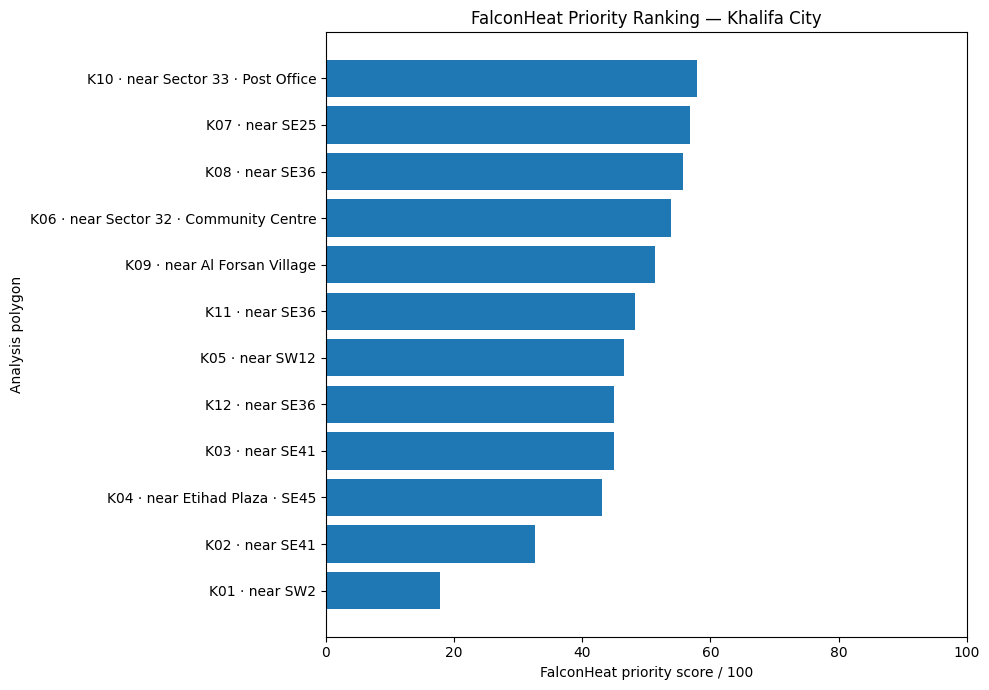

In [ ]:
ordered = df.sort_values("risk_score", ascending=True)

plt.figure(figsize=(10, 7))
plt.barh(ordered["display_name"], ordered["risk_score"])
plt.xlabel("FalconHeat priority score / 100")
plt.ylabel("Analysis polygon")
plt.title("FalconHeat Priority Ranking — Khalifa City")
plt.xlim(0, 100)

save_slide_figure("01_priority_ranking.png")

## Figure 2 — Surface heat vs built-up share
This figure shows the relationship between **urban structure** and **measured land-surface temperature**. Marker size represents WorldPop estimated residents.

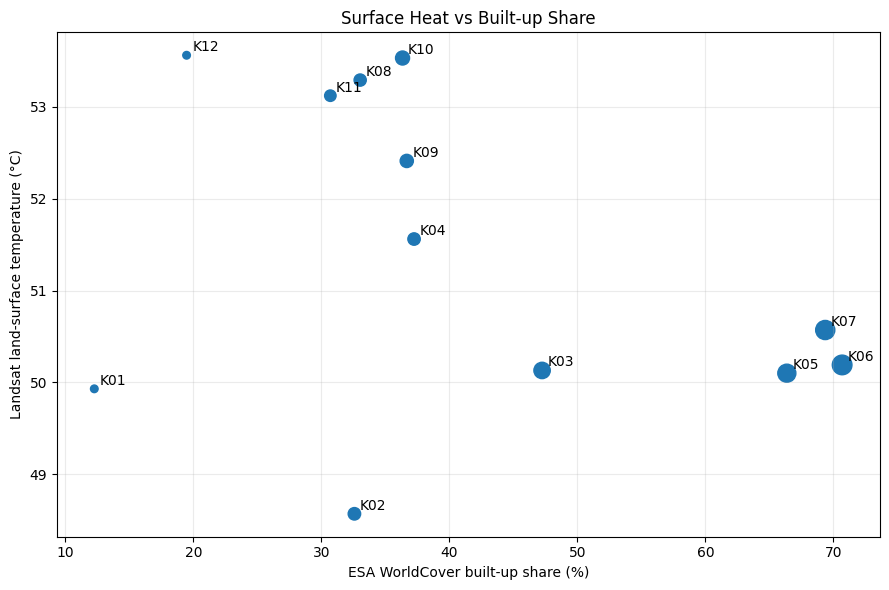

In [ ]:
plt.figure(figsize=(9, 6))
plt.scatter(
    df["built_up"] * 100,
    df["lst_c"],
    s=np.clip(df["population_2026"] / 80, 30, 250)
)

for _, r in df.iterrows():
    plt.annotate(
        r["cell_id"],
        (r["built_up"] * 100, r["lst_c"]),
        xytext=(4, 3),
        textcoords="offset points"
    )

plt.xlabel("ESA WorldCover built-up share (%)")
plt.ylabel("Landsat land-surface temperature (°C)")
plt.title("Surface Heat vs Built-up Share")
plt.grid(alpha=0.25)

save_slide_figure("02_heat_vs_builtup.png")

## Figure 3 — Estimated resident exposure
WorldPop is used as an **estimated population surface**, not as an official census count.

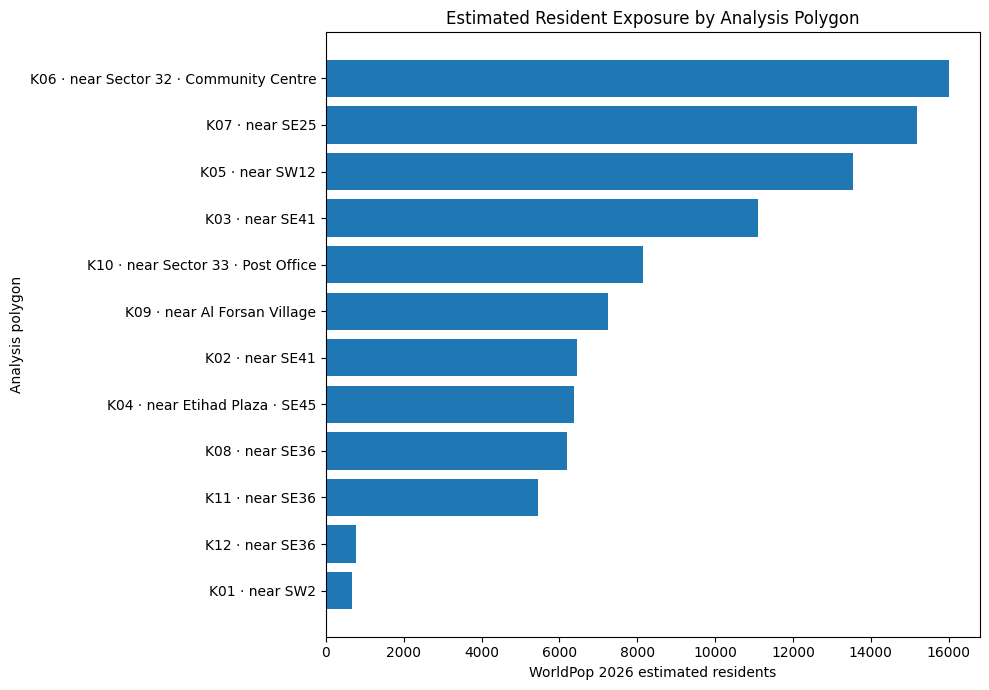

In [ ]:
pop = df.sort_values("population_2026", ascending=True)

plt.figure(figsize=(10, 7))
plt.barh(pop["display_name"], pop["population_2026"])
plt.xlabel("WorldPop 2026 estimated residents")
plt.ylabel("Analysis polygon")
plt.title("Estimated Resident Exposure by Analysis Polygon")

save_slide_figure("03_population_exposure.png")

## Figure 4 — Sentinel-2 NDVI: 2021 vs 2026
NDVI provides the vegetation signal. The comparison uses the same Jul–Sep seasonal window to reduce seasonal bias.

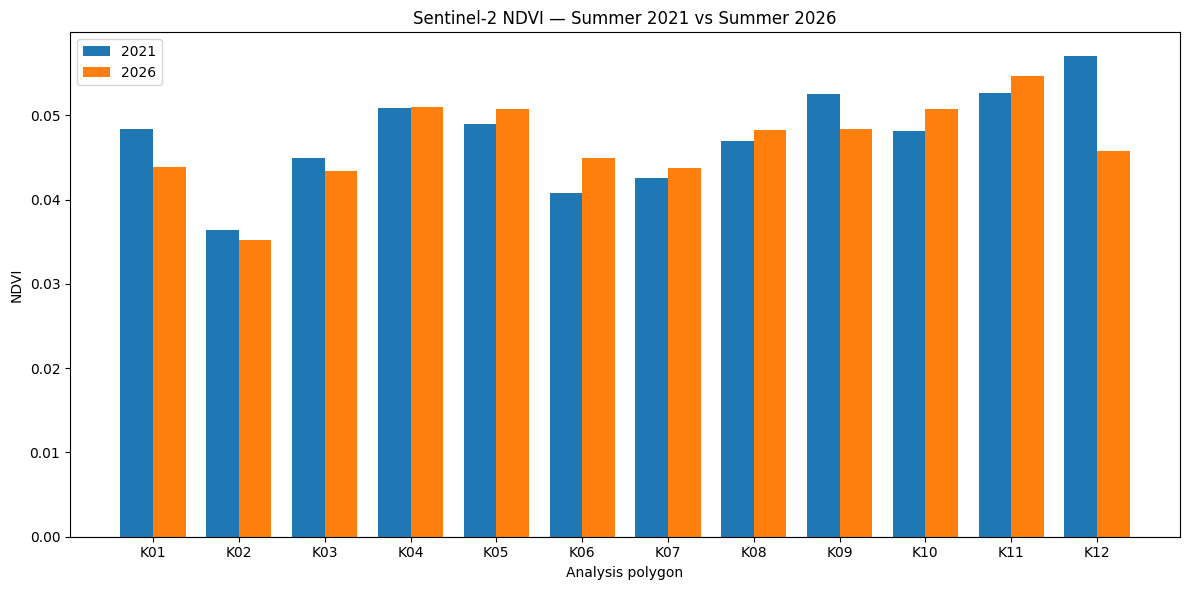

In [ ]:
nd = df.sort_values("cell_id")
x = np.arange(len(nd))
w = 0.38

plt.figure(figsize=(12, 6))
plt.bar(x - w/2, nd["ndvi_2021"], width=w, label="2021")
plt.bar(x + w/2, nd["ndvi"], width=w, label="2026")
plt.axhline(0, linewidth=0.8)
plt.xticks(x, nd["cell_id"])
plt.ylabel("NDVI")
plt.xlabel("Analysis polygon")
plt.title("Sentinel-2 NDVI — Summer 2021 vs Summer 2026")
plt.legend()

save_slide_figure("04_ndvi_2021_vs_2026.png")

## Figure 5 — Sentinel-2 NDBI: 2021 vs 2026
NDBI is treated as a **spectral built-up signal**, not as exact building-area measurement.

### Important result
In the reviewed FalconHeat run, **no polygon has positive ΔNDBI**. FalconHeat therefore does **not** claim that this single comparison proves urban expansion.

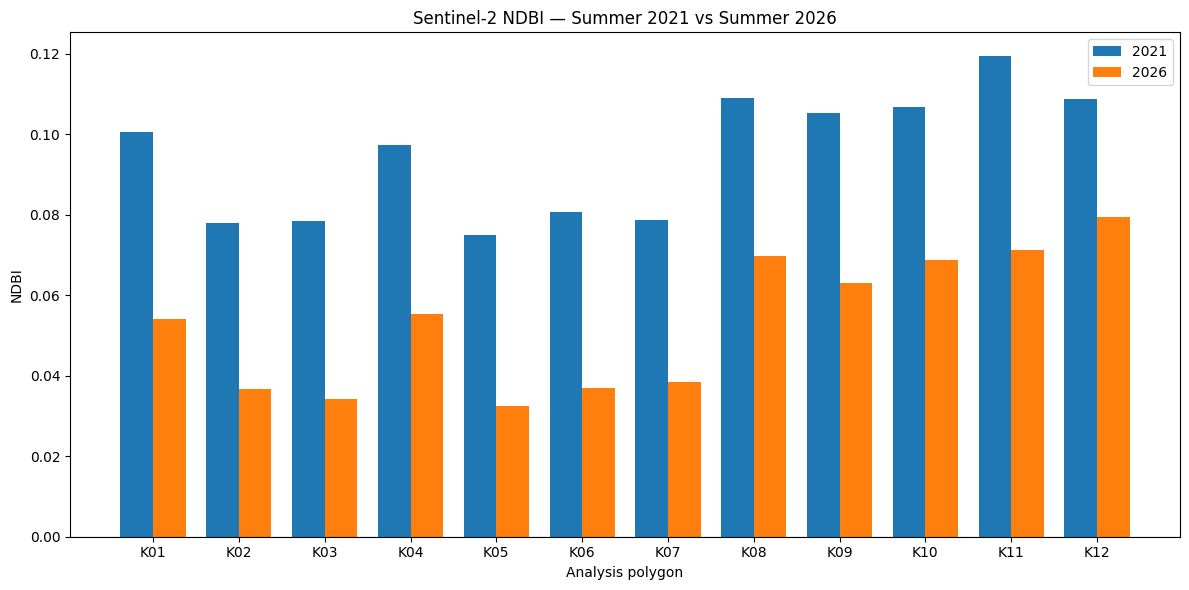

In [ ]:
plt.figure(figsize=(12, 6))
plt.bar(x - w/2, nd["ndbi_2021"], width=w, label="2021")
plt.bar(x + w/2, nd["ndbi"], width=w, label="2026")
plt.axhline(0, linewidth=0.8)
plt.xticks(x, nd["cell_id"])
plt.ylabel("NDBI")
plt.xlabel("Analysis polygon")
plt.title("Sentinel-2 NDBI — Summer 2021 vs Summer 2026")
plt.legend()

save_slide_figure("05_ndbi_2021_vs_2026.png")

## Figure 6 — Explainability: why the top areas rank highest
The FalconHeat score is not a black box. This stacked chart shows how temperature, built-up land, vegetation, population and temporal-change evidence contribute to the top five scores.

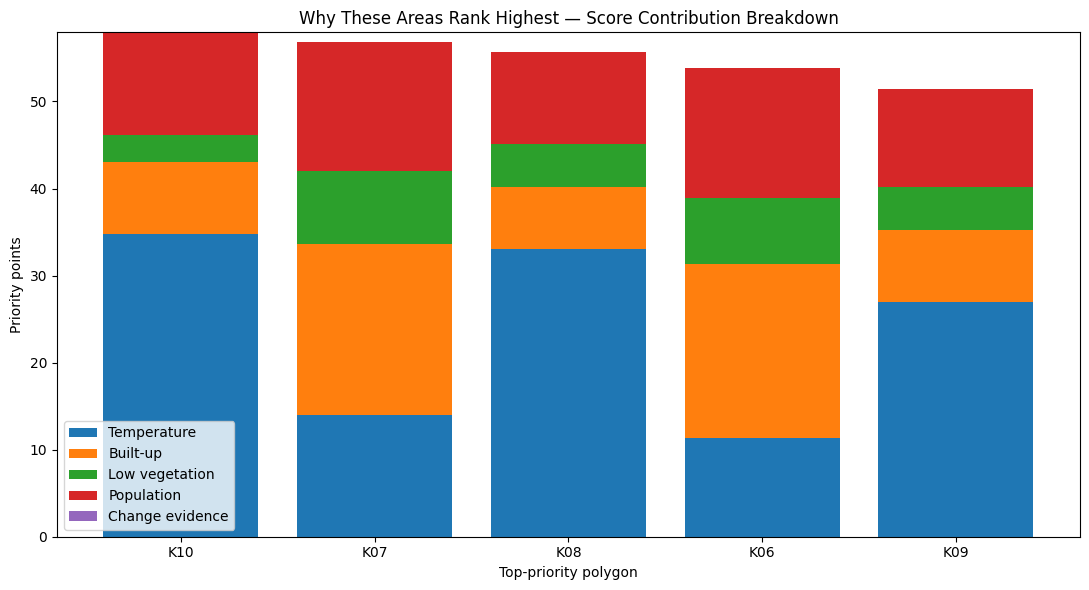

In [ ]:
top5 = df.nlargest(5, "risk_score").copy()

drivers = [
    ("Temperature", "contrib_temperature"),
    ("Built-up", "contrib_built_up"),
    ("Low vegetation", "contrib_low_vegetation"),
    ("Population", "contrib_population"),
    ("Change evidence", "contrib_urban_change"),
]

plt.figure(figsize=(11, 6))
bottom = np.zeros(len(top5))

for label, col in drivers:
    vals = top5[col].to_numpy(dtype=float)
    plt.bar(top5["cell_id"], vals, bottom=bottom, label=label)
    bottom += vals

plt.ylabel("Priority points")
plt.xlabel("Top-priority polygon")
plt.title("Why These Areas Rank Highest — Score Contribution Breakdown")
plt.legend()

save_slide_figure("06_top5_driver_contributions.png")

## Figure 7 — Static FalconHeat priority map
The polygons are analytical units clipped to the Khalifa City **study AOI**. They are not official municipal sector boundaries.

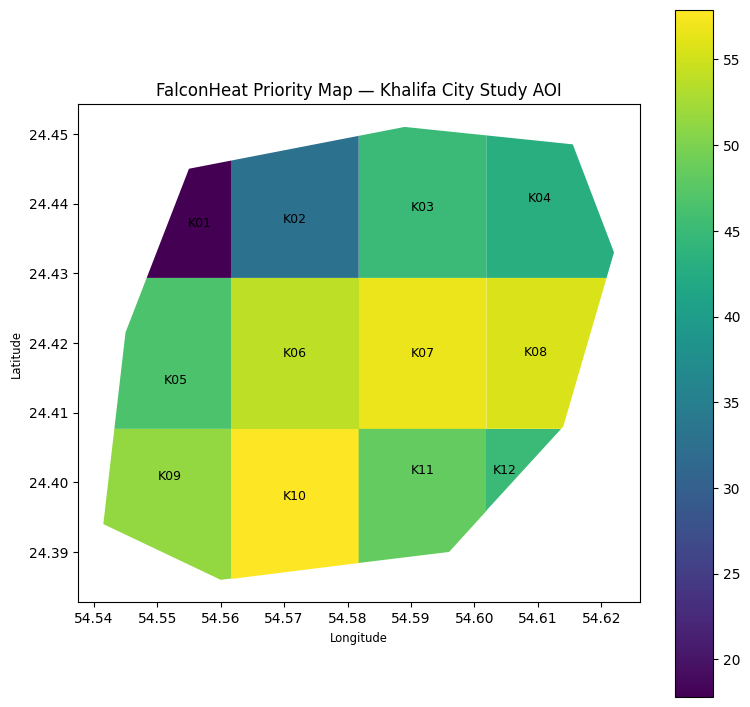

In [ ]:
import geopandas as gpd
from shapely.geometry import shape

map_df = df.copy()
map_df["geometry"] = map_df["geometry_geojson"].apply(
    lambda g: shape(json.loads(g)) if isinstance(g, str) else shape(g)
)
gdf = gpd.GeoDataFrame(map_df, geometry="geometry", crs="EPSG:4326")

fig, ax = plt.subplots(figsize=(8, 8))
gdf.plot(column="risk_score", legend=True, ax=ax)

for _, r in gdf.iterrows():
    p = r.geometry.representative_point()
    ax.annotate(r["cell_id"], (p.x, p.y), ha="center", va="center", fontsize=9)

ax.set_title("FalconHeat Priority Map — Khalifa City Study AOI")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.tight_layout()
plt.savefig(FIG_DIR / "07_priority_map.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

## Figure 8 — Scenario Lab example
This is a **sensitivity test**, not a forecast. It shows how the relative planning index changes under user-specified assumptions.

Current score: 57.9
Illustrative scenario score: 38.6
Scenario level: Moderate


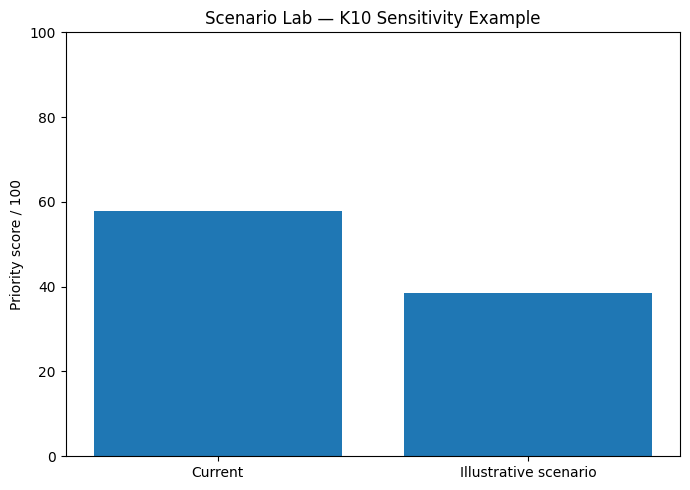

In [ ]:
k10_idx = int(df.index[df["cell_id"].eq("K10")][0])

scenario = scenario_score(
    df,
    k10_idx,
    lst_delta_c=-2.0,
    ndvi_delta=0.05,
    built_delta=-0.05,
    exposure_reduction_pct=10
)

baseline = float(df.loc[k10_idx, "risk_score"])

print("Current score:", baseline)
print("Illustrative scenario score:", scenario["score"])
print("Scenario level:", scenario["level"])

plt.figure(figsize=(7, 5))
plt.bar(["Current", "Illustrative scenario"], [baseline, scenario["score"]])
plt.ylabel("Priority score / 100")
plt.title("Scenario Lab — K10 Sensitivity Example")
plt.ylim(0, 100)

save_slide_figure("08_k10_scenario.png")

## Figure 9 — Evidence completeness
This is **not a statistical confidence interval**. It summarizes data availability, scene/cloud metadata, AOI coverage and exposure-data availability.

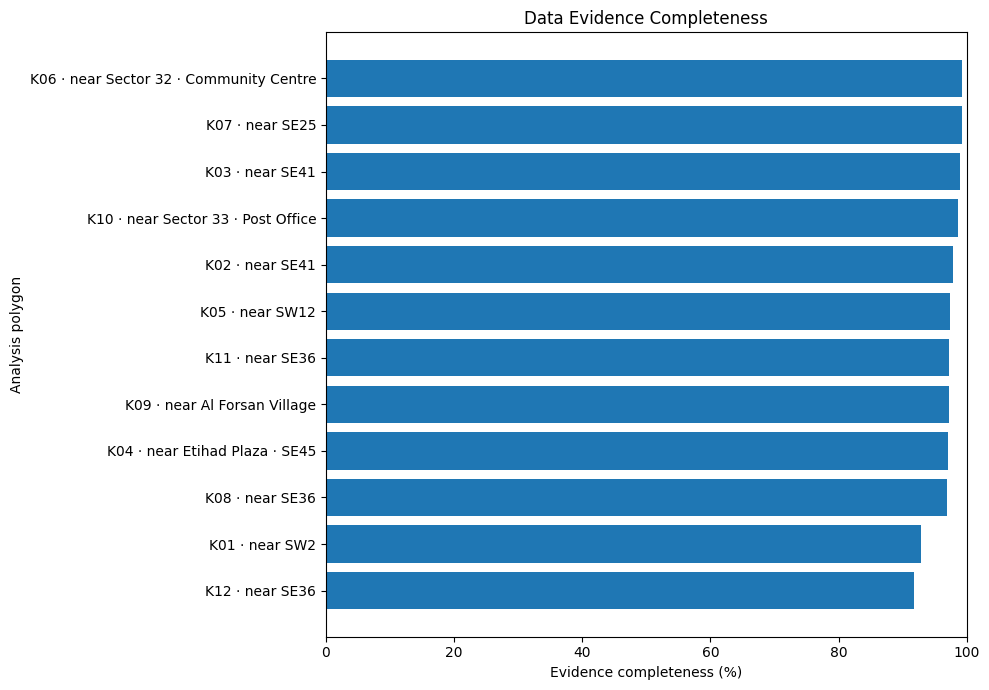

In [ ]:
conf = df.sort_values("data_confidence", ascending=True)

plt.figure(figsize=(10, 7))
plt.barh(conf["display_name"], conf["data_confidence"])
plt.xlabel("Evidence completeness (%)")
plt.ylabel("Analysis polygon")
plt.title("Data Evidence Completeness")
plt.xlim(0, 100)

save_slide_figure("09_evidence_completeness.png")